---
## Final Research Results

The following analysis consolidates detector performance,
confidence intervals, and participant-level outcomes.

**Important limitations:**

- Small, selectively sampled research subset.
- Previously explored recordings were later evaluated.
- Standardized and resampled signal representation.
- Limited independent power-line participants.
- No artifact removal or signal reconstruction.
- No demonstrated clinical preservation of pathology.

These results support an exploratory interference-screening
prototype rather than a clinically validated system.

NEUROSIGNAL-QC — FINAL RESEARCH RESULTS

Dataset:
EEG clips analyzed: 225
Participants: 38
Hospitals: 2

Detector:
Two-feature spectral AND rule
Threshold percentile: 95
No machine-learning model required.

FINAL CROSS-HOSPITAL PERFORMANCE


,Transfer,Target Clips,Target Participants,Power-line Detected,Power-line Total,Sensitivity (%),Specificity (%),False Positives,Pathological Flagged,Pathological Total,Participant Complete Detection (%)
0,Mayo -> FNUSA,105,14,15,15,100.0,100.00,0,0,30,100.0
1,FNUSA -> Mayo,120,24,27,30,90.0,95.56,4,0,30,75.0


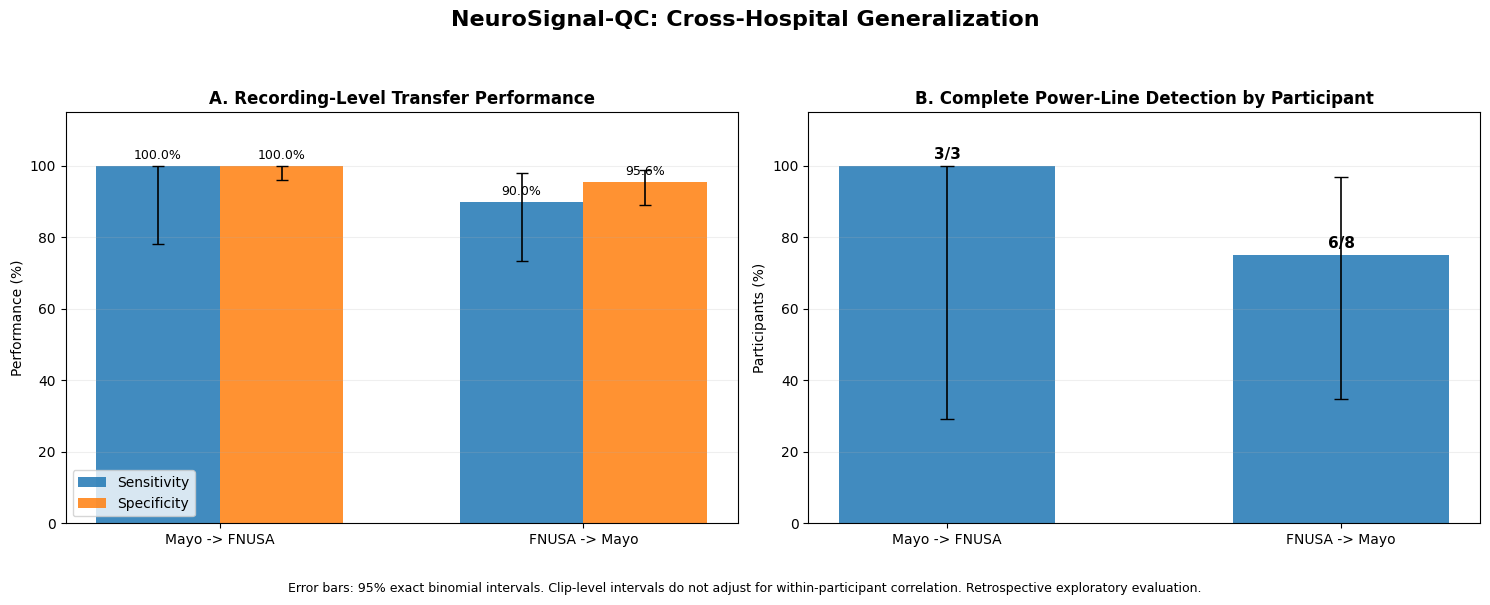


FINAL RESEARCH INTEGRITY CHECKS
Cross-hospital experiments verified: 2
Total target clips across transfer directions: 225
Pathological clips flagged: 0
Pathological clips evaluated: 60

No detector thresholds modified.
No models retrained.
No additional data downloaded.

Final research result consolidation complete.


In [26]:
# ============================================================
# NEUROSIGNAL-QC
# FINALIZATION — CELL 1
# Consolidated Research Results and Performance Visualization
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# ------------------------------------------------------------
# 1. Verify required research outputs
# ------------------------------------------------------------

required_objects = [
    "cross_hospital_results_df",
    "uncertainty_df",
    "participant_reliability_df",
    "phase3_features_df",
    "phase3_train_df",
    "phase3_test_df"
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing notebook results: {missing}"
    )

print("=" * 75)
print("NEUROSIGNAL-QC — FINAL RESEARCH RESULTS")
print("=" * 75)

# ------------------------------------------------------------
# 2. Dataset and detector summary
# ------------------------------------------------------------

dataset_df = phase3_features_df.copy()

dataset_df["Patient_ID"] = (
    dataset_df["Hospital"].astype(str)
    + "_"
    + dataset_df["Subject"]
        .astype(str)
        .str.replace(r"^sub-", "", regex=True)
        .str.zfill(3)
)

n_clips = len(dataset_df)
n_participants = dataset_df["Patient_ID"].nunique()

assert n_clips == 225
assert n_participants == 38

print("\nDataset:")
print("EEG clips analyzed:", n_clips)
print("Participants:", n_participants)
print("Hospitals:", dataset_df["Hospital"].nunique())

print("\nDetector:")
print("Two-feature spectral AND rule")
print("Threshold percentile: 95")
print("No machine-learning model required.")

# ------------------------------------------------------------
# 3. Consolidate cross-hospital performance
# ------------------------------------------------------------

results = cross_hospital_results_df.copy()

results["Transfer"] = (
    results["Source"]
    + " -> "
    + results["Target"]
)

summary_records = []

for _, row in results.iterrows():

    transfer = row["Transfer"]

    # Retrieve clip-level confidence intervals
    ci_rows = uncertainty_df[
        uncertainty_df["Transfer"] == transfer
    ]

    sensitivity_ci = ci_rows[
        ci_rows["Metric"] == "Power-line sensitivity"
    ].iloc[0]

    specificity_ci = ci_rows[
        ci_rows["Metric"] == "Non-power-line specificity"
    ].iloc[0]

    # Retrieve participant-level complete-detection results
    participant_row = participant_reliability_df[
        (
            participant_reliability_df["Transfer"]
            == transfer
        )
        &
        (
            participant_reliability_df["Metric"]
            == "All Power-line Clips Detected"
        )
    ].iloc[0]

    summary_records.append({
        "Transfer": transfer,
        "Source Participants":
            int(row["Source Participants"]),
        "Target Participants":
            int(row["Target Participants"]),
        "Target Clips":
            int(row["Target Clips"]),
        "Power-line Detected":
            int(row["TP"]),
        "Power-line Total":
            int(row["TP"] + row["FN"]),
        "Sensitivity (%)":
            float(row["Sensitivity (%)"]),
        "Sensitivity CI Lower":
            float(sensitivity_ci["95% CI Lower"]),
        "Sensitivity CI Upper":
            float(sensitivity_ci["95% CI Upper"]),
        "Specificity (%)":
            float(row["Specificity (%)"]),
        "Specificity CI Lower":
            float(specificity_ci["95% CI Lower"]),
        "Specificity CI Upper":
            float(specificity_ci["95% CI Upper"]),
        "False Positives":
            int(row["FP"]),
        "Pathological Flagged":
            int(row["Pathological Flagged"]),
        "Pathological Total":
            int(row["Pathological Total"]),
        "Participants Fully Detected":
            int(participant_row["Events"]),
        "Power-line Participants":
            int(participant_row["Participants"]),
        "Participant Complete Detection (%)":
            float(participant_row["Rate (%)"]),
        "Participant CI Lower":
            float(participant_row["95% CI Lower"]),
        "Participant CI Upper":
            float(participant_row["95% CI Upper"])
    })

final_results_df = pd.DataFrame(summary_records)

# ------------------------------------------------------------
# 4. Display final performance table
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL CROSS-HOSPITAL PERFORMANCE")
print("=" * 75)

display(
    final_results_df[
        [
            "Transfer",
            "Target Clips",
            "Target Participants",
            "Power-line Detected",
            "Power-line Total",
            "Sensitivity (%)",
            "Specificity (%)",
            "False Positives",
            "Pathological Flagged",
            "Pathological Total",
            "Participant Complete Detection (%)"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# 5. Publication-style performance visualization
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6)
)

transfers = final_results_df["Transfer"].tolist()
x = np.arange(len(transfers))

# ------------------------------------------------------------
# Panel A — Recording-level performance
# ------------------------------------------------------------

ax = axes[0]

width = 0.34

metrics = [
    (
        "Sensitivity (%)",
        "Sensitivity CI Lower",
        "Sensitivity CI Upper",
        "Sensitivity"
    ),
    (
        "Specificity (%)",
        "Specificity CI Lower",
        "Specificity CI Upper",
        "Specificity"
    )
]

for j, (estimate_col, lower_col, upper_col, label) in enumerate(metrics):

    estimates = final_results_df[
        estimate_col
    ].to_numpy(dtype=float)

    lower = final_results_df[
        lower_col
    ].to_numpy(dtype=float)

    upper = final_results_df[
        upper_col
    ].to_numpy(dtype=float)

    positions = x + (j - 0.5) * width

    bars = ax.bar(
        positions,
        estimates,
        width=width,
        label=label,
        alpha=0.85
    )

    ax.errorbar(
        positions,
        estimates,
        yerr=[
            np.maximum(estimates - lower, 0),
            np.maximum(upper - estimates, 0)
        ],
        fmt="none",
        color="black",
        capsize=4,
        linewidth=1.2
    )

    for bar, value in zip(bars, estimates):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 2,
            f"{value:.1f}%",
            ha="center",
            fontsize=9
        )

ax.set_xticks(x)
ax.set_xticklabels(transfers)

ax.set_ylim(0, 115)

ax.set_ylabel("Performance (%)")

ax.set_title(
    "A. Recording-Level Transfer Performance",
    fontweight="bold"
)

ax.legend(loc="lower left")
ax.grid(axis="y", alpha=0.2)

# ------------------------------------------------------------
# Panel B — Participant-level complete detection
# ------------------------------------------------------------

ax = axes[1]

participant_rates = final_results_df[
    "Participant Complete Detection (%)"
].to_numpy(dtype=float)

participant_lower = final_results_df[
    "Participant CI Lower"
].to_numpy(dtype=float)

participant_upper = final_results_df[
    "Participant CI Upper"
].to_numpy(dtype=float)

bars = ax.bar(
    x,
    participant_rates,
    width=0.55,
    alpha=0.85
)

ax.errorbar(
    x,
    participant_rates,
    yerr=[
        np.maximum(
            participant_rates - participant_lower,
            0
        ),
        np.maximum(
            participant_upper - participant_rates,
            0
        )
    ],
    fmt="none",
    color="black",
    capsize=5,
    linewidth=1.2
)

for i, bar in enumerate(bars):

    detected = int(
        final_results_df.iloc[i][
            "Participants Fully Detected"
        ]
    )

    total = int(
        final_results_df.iloc[i][
            "Power-line Participants"
        ]
    )

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        participant_rates[i] + 2,
        f"{detected}/{total}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_xticks(x)
ax.set_xticklabels(transfers)

ax.set_ylim(0, 115)

ax.set_ylabel("Participants (%)")

ax.set_title(
    "B. Complete Power-Line Detection by Participant",
    fontweight="bold"
)

ax.grid(axis="y", alpha=0.2)

# ------------------------------------------------------------
# 6. Figure formatting
# ------------------------------------------------------------

fig.suptitle(
    "NeuroSignal-QC: Cross-Hospital Generalization",
    fontsize=16,
    fontweight="bold"
)

fig.text(
    0.5,
    0.01,
    "Error bars: 95% exact binomial intervals. "
    "Clip-level intervals do not adjust for within-participant correlation. "
    "Retrospective exploratory evaluation.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.06, 1, 0.93])

plt.show()

# ------------------------------------------------------------
# 7. Final research integrity checks
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL RESEARCH INTEGRITY CHECKS")
print("=" * 75)

assert len(final_results_df) == 2

assert (
    final_results_df["Target Clips"].sum()
    == len(dataset_df)
)

assert (
    final_results_df["Pathological Flagged"].sum()
    == 0
)

print("Cross-hospital experiments verified: 2")

print(
    "Total target clips across transfer directions:",
    final_results_df["Target Clips"].sum()
)

print(
    "Pathological clips flagged:",
    final_results_df["Pathological Flagged"].sum()
)

print(
    "Pathological clips evaluated:",
    final_results_df["Pathological Total"].sum()
)

print("\nNo detector thresholds modified.")
print("No models retrained.")
print("No additional data downloaded.")

print(
    "\nFinal research result consolidation complete."
)

### Research Results and Reproducibility Archive

The final analysis exports the feature dataset,
evaluation results, uncertainty estimates,
scientific figure, and dataset provenance metadata.

The exported CSV files represent reproducible
research outputs, not new clinical datasets.

Raw EEG recordings are retrieved from the public
NEMAR sources and are not redistributed.

In [27]:
# ============================================================
# NEUROSIGNAL-QC
# FINALIZATION — CELL 2
# Research Results, Figures, and Reproducibility Archive
# ============================================================

import json
import pandas as pd

from pathlib import Path
from IPython.display import display

# ------------------------------------------------------------
# 1. Create project directories
# ------------------------------------------------------------

PROJECT_DIR = Path("NeuroSignal-QC")

RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"
METADATA_DIR = PROJECT_DIR / "metadata"

for directory in [
    PROJECT_DIR,
    RESULTS_DIR,
    FIGURES_DIR,
    METADATA_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("=" * 70)
print("NEUROSIGNAL-QC — RESEARCH OUTPUT ARCHIVE")
print("=" * 70)

# ------------------------------------------------------------
# 2. Verify final research objects
# ------------------------------------------------------------

required_tables = {
    "spectral_features": phase3_features_df,
    "participant_split": phase3_split_df,
    "development_rules": dev_rule_results_df,
    "participant_disjoint_evaluation": phase3_eval_results_df,
    "cross_hospital_transfer": cross_hospital_results_df,
    "cross_hospital_errors": cross_hospital_errors_df,
    "statistical_uncertainty": uncertainty_df,
    "participant_reliability": participant_reliability_df,
    "final_research_results": final_results_df
}

for name, dataframe in required_tables.items():

    if not isinstance(dataframe, pd.DataFrame):
        raise TypeError(
            f"{name} is not a pandas DataFrame."
        )

print("\nAll required research tables verified.")

# ------------------------------------------------------------
# 3. Export scientific results as CSV
# ------------------------------------------------------------

export_records = []

for name, dataframe in required_tables.items():

    output_path = RESULTS_DIR / f"{name}.csv"

    dataframe.to_csv(
        output_path,
        index=False
    )

    export_records.append({
        "File": output_path.name,
        "Rows": len(dataframe),
        "Columns": len(dataframe.columns),
        "Status": "Saved"
    })

print("\n" + "=" * 70)
print("EXPORTED RESEARCH TABLES")
print("=" * 70)

export_df = pd.DataFrame(export_records)

display(export_df)

# ------------------------------------------------------------
# 4. Save final cross-hospital performance figure
# ------------------------------------------------------------

figure_path = (
    FIGURES_DIR
    / "cross_hospital_performance.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("\nFinal scientific figure saved:")
print(figure_path)

# ------------------------------------------------------------
# 5. Record dataset provenance
# ------------------------------------------------------------

dataset_provenance = {}

for hospital, dataset_id in DATASETS.items():

    dataset_provenance[hospital] = {
        "dataset_id": dataset_id,
        "source_commit": indexes[hospital].get(
            "source_commit",
            "Not reported"
        ),
        "recording_stores": len(
            indexes[hospital]["stores"]
        )
    }

# ------------------------------------------------------------
# 6. Store reproducibility metadata
# ------------------------------------------------------------

research_metadata = {

    "project": "NeuroSignal-QC",

    "title": (
        "Interpretable Power-Line Interference "
        "Screening in Intracranial EEG"
    ),

    "study_type": (
        "Retrospective exploratory "
        "signal-processing investigation"
    ),

    "datasets": dataset_provenance,

    "dataset_characteristics": {
        "signal_type": "Intracranial EEG",
        "original_sampling_rate_hz": 5000,
        "analyzed_sampling_rate_hz": 1000,
        "segment_duration_seconds": 3,
        "original_dataset_segments": 348300,
        "exploratory_pilot_clips": 45,
        "expanded_analysis_clips": 225,
        "expanded_analysis_participants": 38,
        "hospitals": 2
    },

    "spectral_processing": {
        "method": "Welch PSD",
        "window": "Hann",
        "nperseg": 2048,
        "noverlap": 1024,
        "scaling": "density",
        "total_power_band_hz": [1, 150],
        "mains_search_width_hz": 2,
        "background_offsets_hz": [
            [-15, -5],
            [5, 15]
        ]
    },

    "features": [
        "Relative mains-frequency power (%)",
        "Local spectral prominence (dB)"
    ],

    "detector": {
        "type": "Interpretable threshold-based detector",
        "decision_rule": "AND",
        "threshold_calibration": (
            "95th percentile of non-power-line "
            "development recordings"
        ),
        "hospital_mains_frequencies_hz": {
            "Mayo": 60,
            "FNUSA": 50
        }
    },

    "development_evaluation": {
        "development_clips": int(
            len(phase3_train_df)
        ),
        "evaluation_clips": int(
            len(phase3_test_df)
        ),
        "development_participants": int(
            phase3_train_df["Patient_ID"].nunique()
        ),
        "evaluation_participants": int(
            phase3_test_df["Patient_ID"].nunique()
        ),
        "participant_overlap": 0
    },

    "cross_hospital_results": (
        cross_hospital_results_df
        .to_dict(orient="records")
    ),

    "limitations": [
        "Small, selectively sampled research subset",
        "Standardized and resampled signal representation",
        "Some participants contribute multiple clips",
        "Exploratory feature analysis preceded evaluation splits",
        "Cross-hospital transfer is retrospective",
        "Only power-line interference was modeled",
        "No actual signal cleaning was performed",
        "No clinical validation",
        "No demonstrated preservation of pathological waveforms"
    ]
}

metadata_path = (
    METADATA_DIR
    / "research_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        research_metadata,
        file,
        indent=4,
        default=lambda x: (
            x.item()
            if hasattr(x, "item")
            else str(x)
        )
    )

print("\nReproducibility metadata saved:")
print(metadata_path)

# ------------------------------------------------------------
# 7. Verify saved files
# ------------------------------------------------------------

expected_files = (
    list(RESULTS_DIR.glob("*.csv"))
    +
    list(FIGURES_DIR.glob("*.png"))
    +
    list(METADATA_DIR.glob("*.json"))
)

assert len(expected_files) == 11, (
    f"Expected 11 files, found {len(expected_files)}."
)

for file_path in expected_files:

    assert file_path.stat().st_size > 0, (
        f"Empty output file: {file_path}"
    )

# ------------------------------------------------------------
# 8. Final research archive summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RESEARCH ARCHIVE SUMMARY")
print("=" * 70)

print("Project directory:", PROJECT_DIR)

print(
    "Research tables:",
    len(list(RESULTS_DIR.glob("*.csv")))
)

print(
    "Scientific figures:",
    len(list(FIGURES_DIR.glob("*.png")))
)

print(
    "Metadata files:",
    len(list(METADATA_DIR.glob("*.json")))
)

print(
    "Total files:",
    len(expected_files)
)

print("\nResearch results archived successfully.")
print("No detector thresholds were modified.")
print("No models were retrained.")
print("No additional EEG data were retrieved.")

NEUROSIGNAL-QC — RESEARCH OUTPUT ARCHIVE

All required research tables verified.

EXPORTED RESEARCH TABLES


,File,Rows,Columns,Status
0,spectral_features.csv,225,9,Saved
1,participant_split.csv,225,12,Saved
2,development_rules.csv,4,8,Saved
3,participant_disjoint_evaluation.csv,71,14,Saved
4,cross_hospital_transfer.csv,2,18,Saved
5,cross_hospital_errors.csv,7,14,Saved
6,statistical_uncertainty.csv,6,7,Saved
7,participant_reliability.csv,6,7,Saved
8,final_research_results.csv,2,20,Saved



Final scientific figure saved:
NeuroSignal-QC/figures/cross_hospital_performance.png

Reproducibility metadata saved:
NeuroSignal-QC/metadata/research_metadata.json

RESEARCH ARCHIVE SUMMARY
Project directory: NeuroSignal-QC
Research tables: 9
Scientific figures: 1
Metadata files: 1
Total files: 11

Research results archived successfully.
No detector thresholds were modified.
No models were retrained.
No additional EEG data were retrieved.
